## Step 0: setup

Keras 3 runs on TensorFlow, JAX or PyTorch; everything here works on any of them. Fixing the seed makes weight initialisation and shuffling repeatable, so your numbers match between runs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)    # same run every time
print(keras.__version__, keras.backend.backend())

3.15.1 tensorflow


## Step 1: load the data and look at it

MNIST has 60,000 training and 10,000 test images of handwritten digits, each 28 × 28 pixels with values 0 to 255. Keras downloads it the first time (about 11 MB).

Always look at raw data before modelling: some of these digits are genuinely ambiguous.

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
uint8 0 255
[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


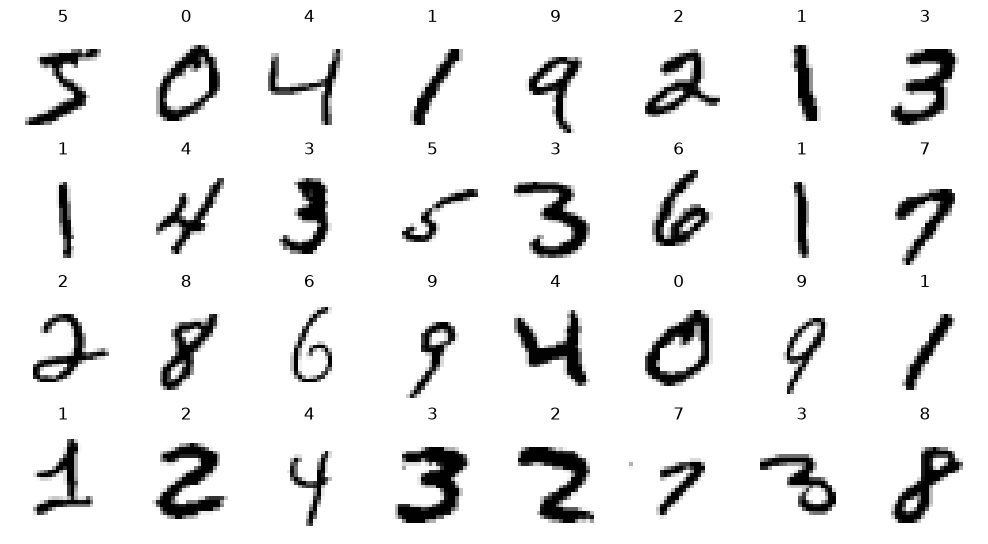

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(x_train.shape, y_train.shape)  # (60000, 28, 28) (60000,)
print(x_test.shape, y_test.shape)    # (10000, 28, 28) (10000,)
print(x_train.dtype, x_train.min(), x_train.max())  # uint8 0 255
print(np.bincount(y_train))          # about 6,000 per digit

fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Question:** what is one *sample* here, and what is its *target*?

<details><summary>Show the answer</summary>

One sample is one 28 × 28 image. Its target is the digit it shows, an integer from 0 to 9. The ten classes are roughly balanced, so plain accuracy is a fair metric; with 95% of one class it would not be.

</details>

## Step 2: flatten and scale

- **Flatten:** a Dense layer takes a vector, so each 28 × 28 image becomes 784 numbers.
- **Scale to [0, 1]:** small, similar-sized inputs keep early training stable. This is the input normalisation from Section 4.
- **Labels stay integers**, so we will use `sparse_categorical_crossentropy`.

In [ ]:
x_train_flat = x_train.reshape(-1, 28 * 28).astype("float32") / 255
x_test_flat = x_test.reshape(-1, 28 * 28).astype("float32") / 255

print(x_train_flat.shape)                      # (60000, 784)
print(x_train_flat.min(), x_train_flat.max())  # 0.0 1.0
print(y_train[:10])          # [5 0 4 1 9 2 1 3 1 4] integer labels

plt.figure(figsize=(10, 2))
plt.plot(x_train_flat[0])    # what the network actually sees
plt.xlabel("pixel index")
plt.show()

> **Thought experiment:** shuffle all 784 pixels with one fixed permutation, the same for every image. The MLP's accuracy would not change: it ignores where pixels are. Convolutional networks fix that later in the module.

## Step 3: build the model

One hidden Dense layer with 128 ReLU units, and an output layer with 10 softmax units: one probability per digit (Section 2).

**Question:** before running the next cell, how many parameters does this model have?

<details><summary>Show the answer</summary>

Each Dense layer has (inputs × units) weights plus one bias per unit.

| layer | calculation | parameters |
|---|---|---|
| hidden | 784 × 128 + 128 | 100,480 |
| output | 128 × 10 + 10 | 1,290 |
| total | | 101,770 |

99% of the parameters sit in the first layer: wide inputs are expensive.

</details>

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu", name="hidden"),
    layers.Dense(10, activation="softmax", name="output"),
])
model.summary()

## Step 4: compile, then sanity-check before training

The **loss** is what the optimiser minimises. **Metrics** are only reported; they do not affect training. We check on training data: the test set stays untouched until Step 7.

In [ ]:
model.compile(
    optimizer="adam",                        # how weights are updated
    loss="sparse_categorical_crossentropy",  # integer labels 0..9
    metrics=["accuracy"],                    # what we report
)

# Before training: what should the loss be?
loss0, acc0 = model.evaluate(x_train_flat[:2000], y_train[:2000],
                             verbose=0)
print(f"untrained: loss={loss0:.3f}  accuracy={acc0:.3f}")
# expect loss near ln(10) = 2.303 and accuracy near 0.10

**Question:** why should the untrained loss be close to 2.303?

<details><summary>Show the answer</summary>

An untrained network spreads its probability roughly evenly over the 10 classes, so the probability of the true class is about 1/10, and the cross-entropy is −ln(1/10) = ln 10 ≈ 2.303. A value far from that points to a bug: wrong labels, wrong loss, or unscaled inputs.

</details>

## Step 5: train with a validation split

Reading the progress bar:

- `422/422`: 54,000 training images in batches of 128 is 421.9, so 422 steps per epoch (Section 4).
- `loss`, `accuracy`: on the training batches, averaged over the epoch.
- `val_loss`, `val_accuracy`: on the 6,000 held-out images, after the epoch.

`validation_split` takes the **last** 10% of the arrays without shuffling. That is fine for MNIST, but dangerous if your data is sorted by time or by class.

In [ ]:
history = model.fit(
    x_train_flat, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,   # last 6,000 training images
)

## Step 6: plot the learning curves

In [ ]:
h = history.history
ep = range(1, len(h["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, h["loss"], "o-", label="training")
ax1.plot(ep, h["val_loss"], "s--", label="validation")
ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
ax2.plot(ep, h["accuracy"], "o-", label="training")
ax2.plot(ep, h["val_accuracy"], "s--", label="validation")
ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for ax in (ax1, ax2):
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

**Question:** at which epoch is validation loss lowest?

<details><summary>Show the answer</summary>

Read it off your plot, or compute it: `np.argmin(h["val_loss"]) + 1`. After that epoch, further training no longer helps on new data.

</details>

**Question:** is the gap between training and validation growing?

<details><summary>Show the answer</summary>

Usually yes, slowly: training loss keeps falling while validation loss levels off and may start to rise. That growing gap is the start of overfitting (Section 7). Part 2 of this notebook makes it much more visible.

</details>

**Question:** in epoch 1, why can validation accuracy beat training accuracy?

<details><summary>Show the answer</summary>

The training accuracy for an epoch is a running average over all its batches, including the early ones when the weights were still poor. Validation accuracy is measured once, at the end of the epoch, with the improved weights.

</details>

## Step 7: evaluate on the test set, once

Expect roughly **97 to 98%**, against 10% for guessing. Compare with the final validation accuracy: if they are close, validation was a good stand-in for unseen data.

This is the first and only time the test set is used. If you now change the model because of this number, the test set has become a second validation set.

In [ ]:
test_loss, test_acc = model.evaluate(x_test_flat, y_test,
                                     verbose=0)
print(f"test loss = {test_loss:.4f}")
print(f"test accuracy = {test_acc:.4f}")

## Step 8a: what does a prediction look like?

`predict` returns the softmax output: one probability distribution per image. `argmax` turns it into a class. Most bars are a single spike near 1; look for an image where two bars share the probability: the network is unsure, and it usually agrees with your own hesitation.

In [ ]:
probs = model.predict(x_test_flat[:8], verbose=0)
print(probs.shape, probs[0].sum())   # (8, 10) about 1.0
preds = probs.argmax(axis=1)

fig, axes = plt.subplots(2, 8, figsize=(15, 4))
for i in range(8):
    top, bottom = axes[0, i], axes[1, i]
    top.imshow(x_test[i], cmap="gray_r")
    top.set_title(f"true {y_test[i]}, pred {preds[i]}")
    top.axis("off")
    bottom.bar(range(10), probs[i])
    bottom.set_xticks(range(10))
    bottom.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Step 8b: look at the mistakes

The number in brackets is the model's confidence in its wrong answer. Wrong *and* confident (0.95 or more) is the expensive case in engineering, and it is exactly what cross-entropy punishes hardest.

In [ ]:
all_probs = model.predict(x_test_flat, verbose=0)
y_pred = all_probs.argmax(axis=1)
wrong = np.flatnonzero(y_pred != y_test)
print(len(wrong), "of", len(y_test), "test images misclassified")

fig, axes = plt.subplots(3, 8, figsize=(12, 5.5))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(x_test[i], cmap="gray_r")
    conf = all_probs[i, y_pred[i]]
    ax.set_title(f"{y_test[i]} as {y_pred[i]} ({conf:.2f})")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Question:** would a human get these right? Which ones look like labelling errors?

<details><summary>Show the answer</summary>

Many of the mistakes are digits that people also find hard: a 4 that could be a 9, an open 6. A few look like labelling errors. No model can be expected to get those right, and a large model that does fit them on the training set is memorising noise (Section 7).

</details>

## Step 8c: the confusion matrix

Rows are the true digits, columns the predictions. The diagonal holds the correct predictions; every off-diagonal cell is a *specific* confusion: row 4, column 9 counts fours called nines. Typical MLP confusions are shape neighbours such as 4/9, 3/5 and 7/2.

In [ ]:
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_test, y_pred), 1)   # rows: true, cols: predicted

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im)
ax.set(xlabel="predicted", ylabel="true",
       xticks=range(10), yticks=range(10))
for i in range(10):
    for j in range(10):
        dark = cm[i, j] > cm.max() / 2
        ax.text(j, i, cm[i, j], ha="center", va="center",
                fontsize=8, color="white" if dark else "black")
plt.show()

> **Tip:** the diagonal dominates the colour scale. Copy `cm`, set its diagonal to zero with `np.fill_diagonal(cm_off, 0)`, and plot again to see only the errors.

## Step 9: look inside the hidden layer

Column *k* of the hidden layer's kernel holds the 784 weights of hidden unit *k*. Reshaped to 28 × 28, it is an image. The unit computes a dot product of the input with this image: red pixels push it up, blue pull it down. Each unit is a learned template or stroke detector.

This is Section 1 made concrete: \(W\mathbf{x} + \mathbf{b}\) is 128 template matches, and ReLU keeps the positive ones.

In [ ]:
W1, b1 = model.get_layer("hidden").get_weights()
print(W1.shape, b1.shape)   # (784, 128) (128,)

fig, axes = plt.subplots(8, 16, figsize=(16, 8.5))
for k, ax in enumerate(axes.flat):
    w = W1[:, k].reshape(28, 28)
    lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.axis("off")
plt.suptitle("What each hidden unit responds to")
plt.tight_layout()
plt.show()

---
# Part 2: overfitting, on purpose, then fixed

Sections 7 and 8 of the lecture. MNIST with 54,000 training images barely overfits a 128-unit network in 10 epochs, so we make it easy for the model to overfit: **only 2,000 training images** and a **wider network**. Validation uses the same 6,000 images as before.

First, a helper that builds the model, with optional dropout.

In [ ]:
def build_model(hidden=128, dropout=0.0):
    model = keras.Sequential()
    model.add(keras.Input(shape=(784,)))
    model.add(layers.Dense(hidden, activation="relu"))
    if dropout > 0:
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

x_small, y_small = x_train_flat[:2000], y_train[:2000]   # small training set
x_val, y_val = x_train_flat[-6000:], y_train[-6000:]     # same validation images as Step 5

## A. Can the model learn at all?

A working pipeline can memorise 100 samples. If it cannot, look for a bug before tuning anything (Section 6). Being able to overfit is a good sign: it proves the model has enough capacity (Section 7).

In [ ]:
keras.utils.set_random_seed(0)
probe = build_model()
probe.fit(x_train_flat[:100], y_train[:100], epochs=100, verbose=0)
print(probe.evaluate(x_train_flat[:100], y_train[:100], verbose=0))
# accuracy should reach about 1.0

## B. Make it overfit

512 hidden units, 2,000 training images, 40 epochs.

In [ ]:
keras.utils.set_random_seed(0)
big = build_model(hidden=512)
h_big = big.fit(x_small, y_small, epochs=40, batch_size=128,
                validation_data=(x_val, y_val), verbose=0).history

best = int(np.argmin(h_big["val_loss"]))
print(f"lowest validation loss {h_big['val_loss'][best]:.3f} at epoch {best + 1}")
print(f"final: training loss {h_big['loss'][-1]:.4f}, validation loss {h_big['val_loss'][-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(h_big["loss"], label="training")
plt.plot(h_big["val_loss"], "--", label="validation")
plt.axvline(best, color="grey", lw=0.8)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Question:** what happens to training loss and validation loss after the best epoch?

<details><summary>Show the answer</summary>

Training loss keeps falling towards zero: the network is memorising the 2,000 images. Validation loss stops improving and climbs, because the model becomes more and more confident, including on the validation images it gets wrong.

</details>

## C. Fix it: dropout and early stopping

Same data and size, now with 50% dropout after the hidden layer, and early stopping that keeps the best weights (Section 8).

In [ ]:
keras.utils.set_random_seed(0)
reg = build_model(hidden=512, dropout=0.5)
stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
h_reg = reg.fit(x_small, y_small, epochs=100, batch_size=128,
                validation_data=(x_val, y_val), callbacks=[stop],
                verbose=0).history

for name, hh in [("no regularisation", h_big), ("dropout + early stopping", h_reg)]:
    b = int(np.argmin(hh["val_loss"]))
    print(f"{name:26s} lowest val loss {hh['val_loss'][b]:.3f} at epoch {b + 1}, "
          f"val accuracy there {hh['val_accuracy'][b]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(h_big["val_loss"], label="validation, no regularisation")
plt.plot(h_reg["val_loss"], label="validation, dropout + early stopping")
plt.plot(h_reg["loss"], ":", label="training, dropout (measured with dropout on)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Question:** did regularisation help? What should you compare?

<details><summary>Show the answer</summary>

Compare the **lowest** validation loss, not the final one, and when it occurs. A useful regulariser lowers the minimum, not just delays it. Training loss with dropout is higher and noisier because it is measured with dropout switched on; that is expected. Before trusting a small difference, repeat with a few seeds.

</details>

## Exercises

1. **Capacity:** train the full-data model with 32, 128 and 512 hidden units, three seeds each. Compare best validation accuracy and training time.
2. **Learning rate:** compile with `keras.optimizers.Adam(learning_rate=...)` for 1e-2, 1e-3 and 1e-4. What happens to the learning curves?
3. **Batch size:** 32 versus 512 for 5 epochs. Compare accuracy per epoch, and time per epoch.
4. **Weight decay:** in Part 2, add `kernel_regularizer=keras.regularizers.l2(1e-3)` to the hidden layer instead of dropout. Which works better on 2,000 images?
5. **Memorising noise:** shuffle the training labels at random (`np.random.permutation(y_small)`) and train the 512-unit model for 100 epochs. Training accuracy climbs; what does validation accuracy do, and why?